In [2]:

import sqlite3
import pandas as pd

# File locations
csv_path = r"C:\Users\sapka\Downloads\retail_cleaned_for_sql.csv"
db_path = r"C:\Users\sapka\Downloads\retail_analytics.db"

# Connect to SQLite (creates the database if it doesn't exist)
conn = sqlite3.connect(db_path)

# Import CSV into a SQL table
for chunk in pd.read_csv(csv_path, chunksize=50000):
    chunk.to_sql(
        "retail_transactions",
        conn,
        if_exists="append",
        index=False
    )

print("CSV imported into SQLite successfully!")

# Verify the number of rows
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM retail_transactions",
    conn
)

display(result)

print("Database location:", db_path)


CSV imported into SQLite successfully!


,total_rows
0,2066072


Database location: C:\Users\sapka\Downloads\retail_analytics.db


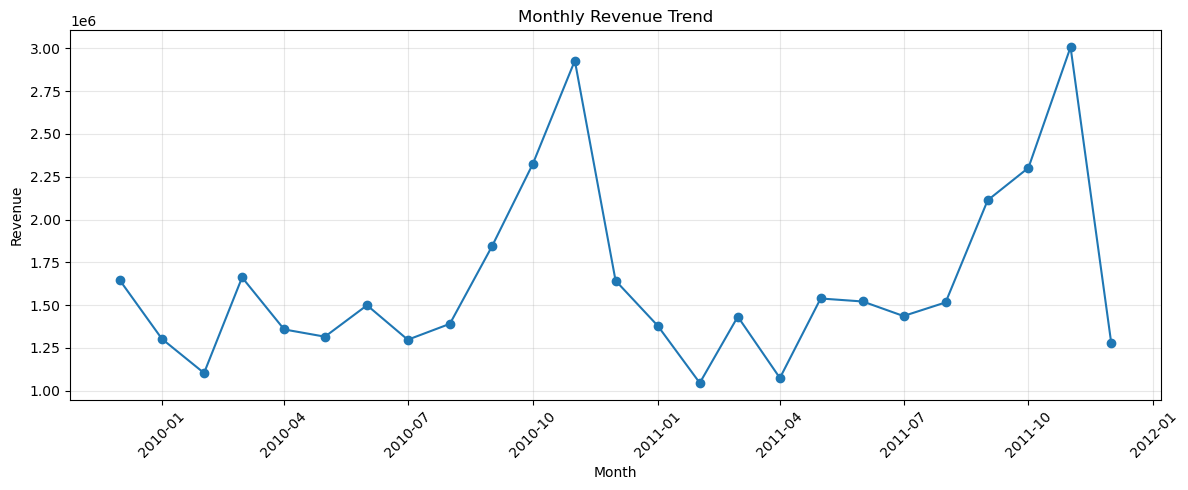

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS Month,
    ROUND(SUM(Quantity * Price), 2) AS Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY Month;
"""

monthly_revenue = pd.read_sql_query(query, conn)

monthly_revenue["Month"] = pd.to_datetime(monthly_revenue["Month"])

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

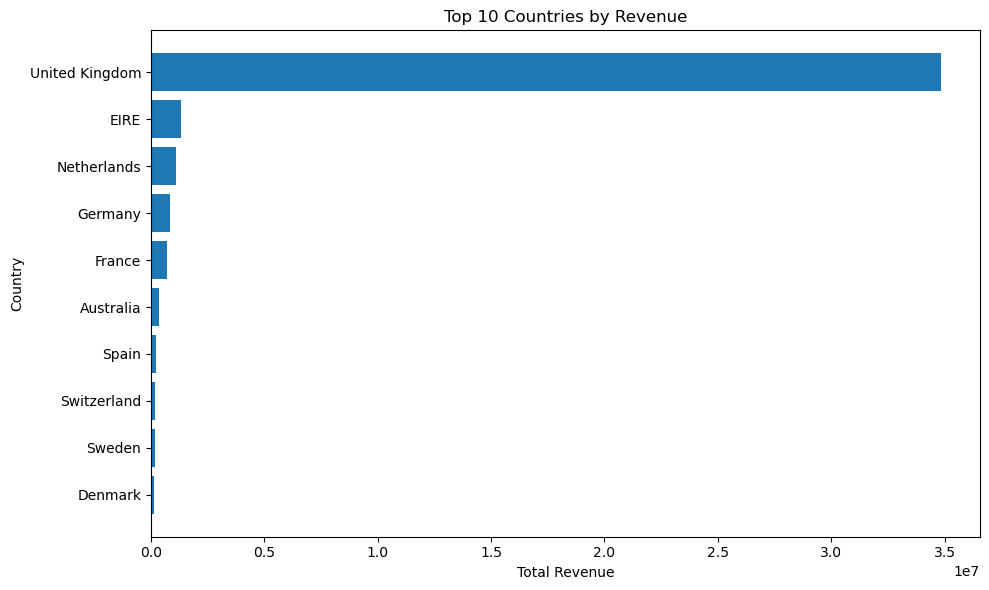

In [4]:
query = """
SELECT
    Country,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

country_revenue = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
plt.barh(
    country_revenue["Country"][::-1],
    country_revenue["Total_Revenue"][::-1]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

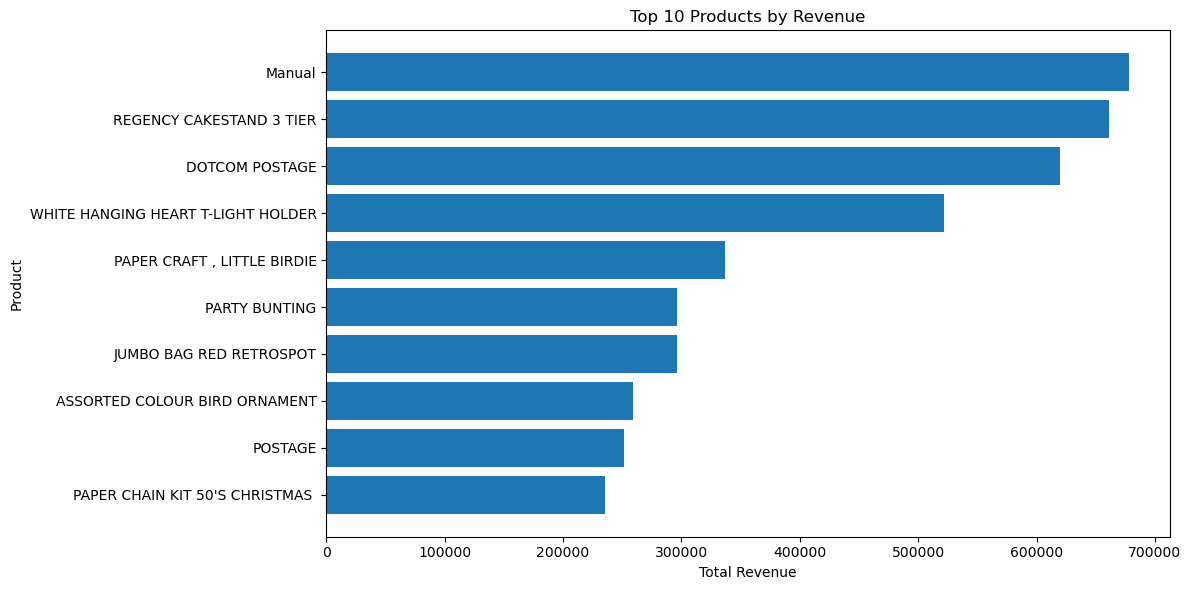

In [5]:
query = """
SELECT
    Description,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND Description IS NOT NULL
GROUP BY Description
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Description"][::-1],
    top_products["Total_Revenue"][::-1]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

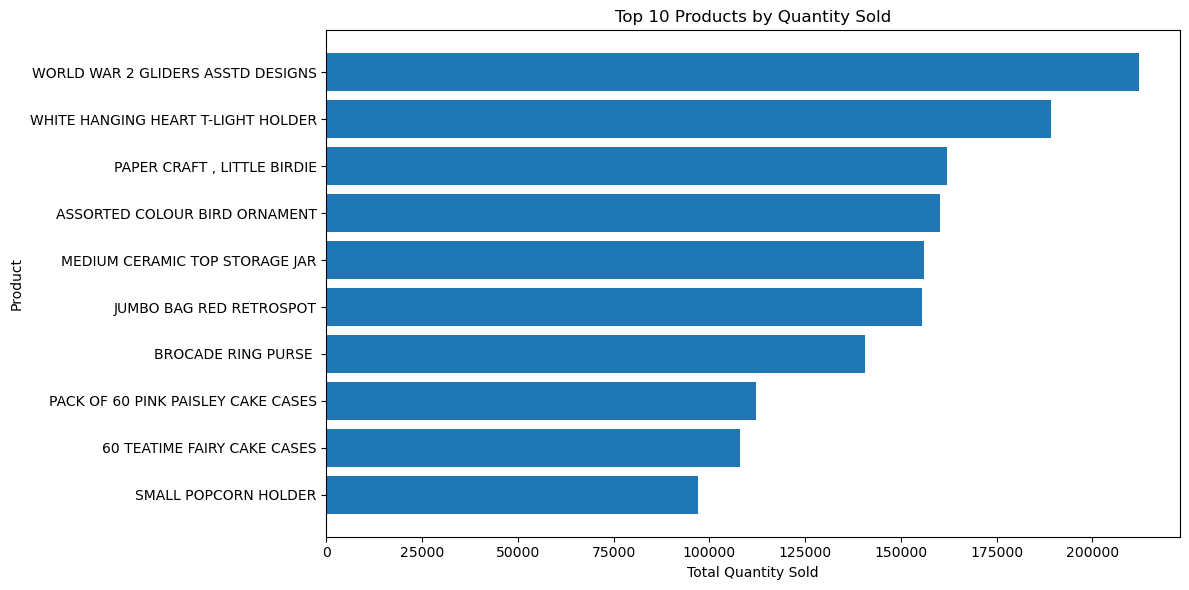

In [6]:
query = """
SELECT
    Description,
    SUM(Quantity) AS Total_Quantity
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND Description IS NOT NULL
GROUP BY Description
ORDER BY Total_Quantity DESC
LIMIT 10;
"""

top_quantity = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))
plt.barh(
    top_quantity["Description"][::-1],
    top_quantity["Total_Quantity"][::-1]
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

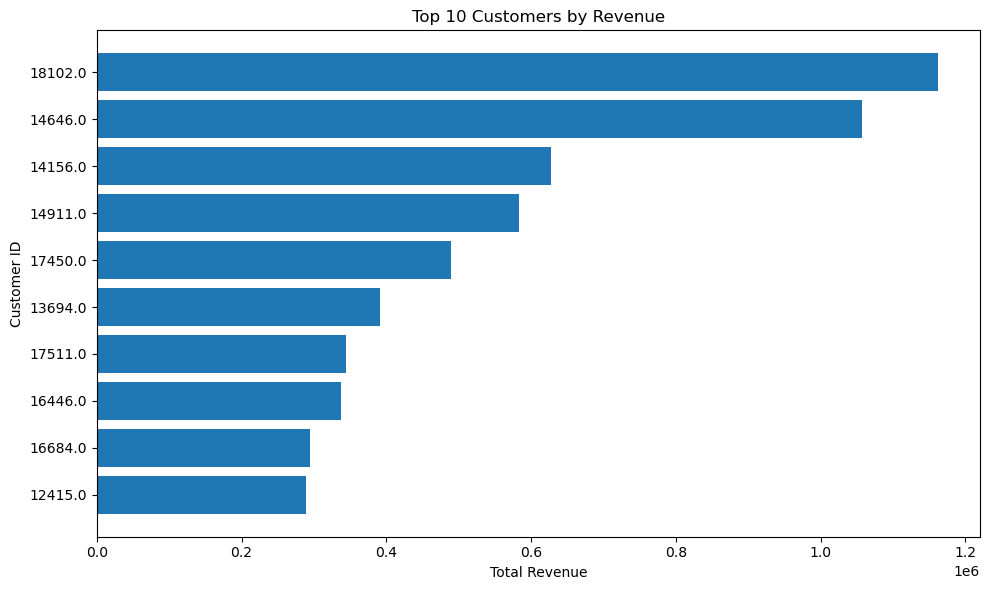

In [7]:
query = """
SELECT
    "Customer ID",
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND "Customer ID" IS NOT NULL
GROUP BY "Customer ID"
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(query, conn)

top_customers["Customer ID"] = (
    top_customers["Customer ID"].astype(str)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_customers["Customer ID"][::-1],
    top_customers["Total_Revenue"][::-1]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

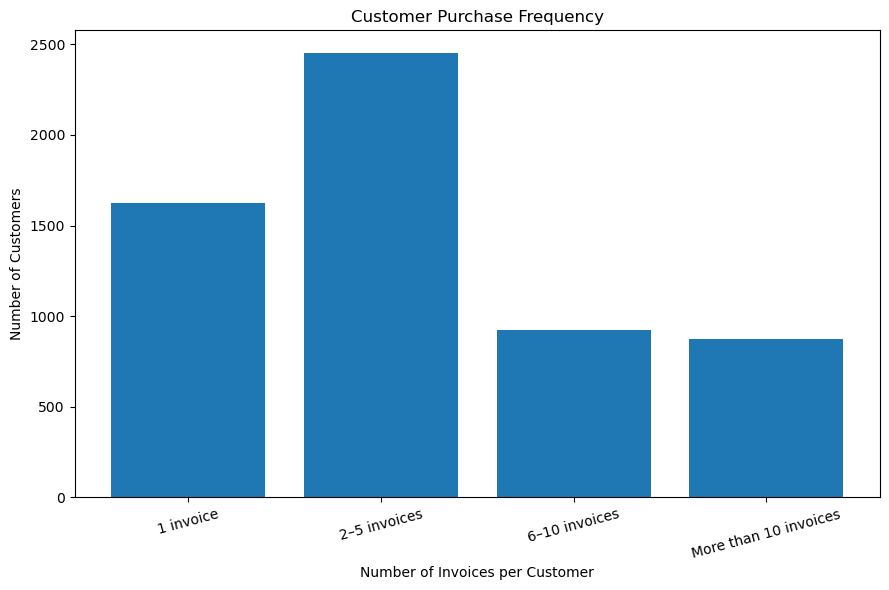

In [8]:
query = """
SELECT
    Invoice_Count,
    COUNT(*) AS Number_of_Customers
FROM (
    SELECT
        "Customer ID",
        COUNT(DISTINCT Invoice) AS Invoice_Count
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND "Customer ID" IS NOT NULL
    GROUP BY "Customer ID"
)
GROUP BY Invoice_Count
ORDER BY Invoice_Count;
"""

purchase_frequency = pd.read_sql_query(query, conn)

purchase_frequency["Purchase_Group"] = purchase_frequency[
    "Invoice_Count"
].apply(
    lambda x: "1 invoice" if x == 1
    else "2–5 invoices" if x <= 5
    else "6–10 invoices" if x <= 10
    else "More than 10 invoices"
)

frequency_summary = (
    purchase_frequency.groupby("Purchase_Group")["Number_of_Customers"]
    .sum()
    .reindex([
        "1 invoice",
        "2–5 invoices",
        "6–10 invoices",
        "More than 10 invoices"
    ])
    .dropna()
)

plt.figure(figsize=(9, 6))
plt.bar(
    frequency_summary.index,
    frequency_summary.values
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Invoices per Customer")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

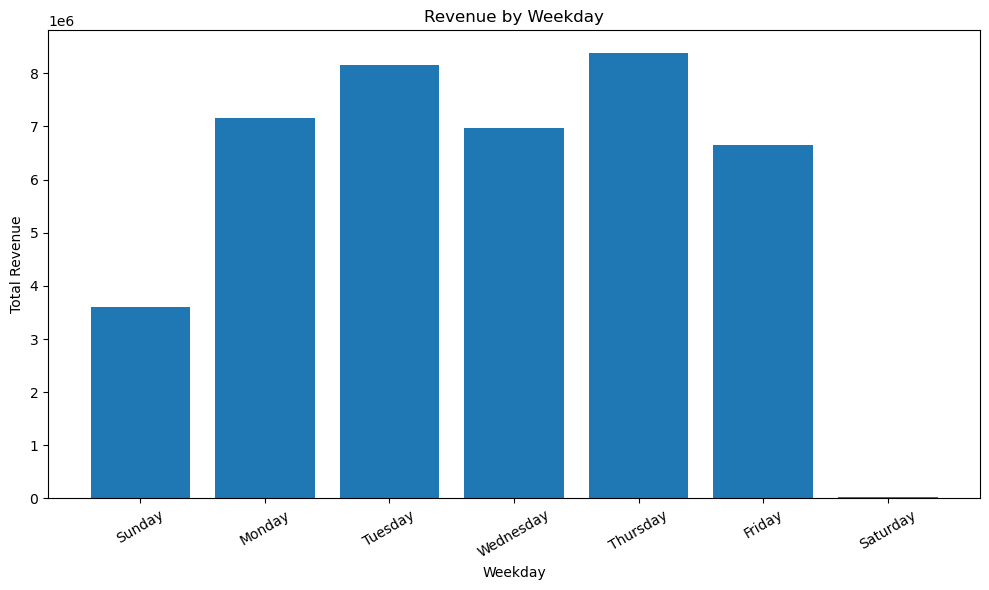

In [9]:
query = """
SELECT
    CASE CAST(strftime('%w', InvoiceDate) AS INTEGER)
        WHEN 0 THEN 'Sunday'
        WHEN 1 THEN 'Monday'
        WHEN 2 THEN 'Tuesday'
        WHEN 3 THEN 'Wednesday'
        WHEN 4 THEN 'Thursday'
        WHEN 5 THEN 'Friday'
        WHEN 6 THEN 'Saturday'
    END AS Weekday,
    CAST(strftime('%w', InvoiceDate) AS INTEGER) AS Day_Number,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Day_Number
ORDER BY Day_Number;
"""

weekday_revenue = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
plt.bar(
    weekday_revenue["Weekday"],
    weekday_revenue["Total_Revenue"]
)

plt.title("Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

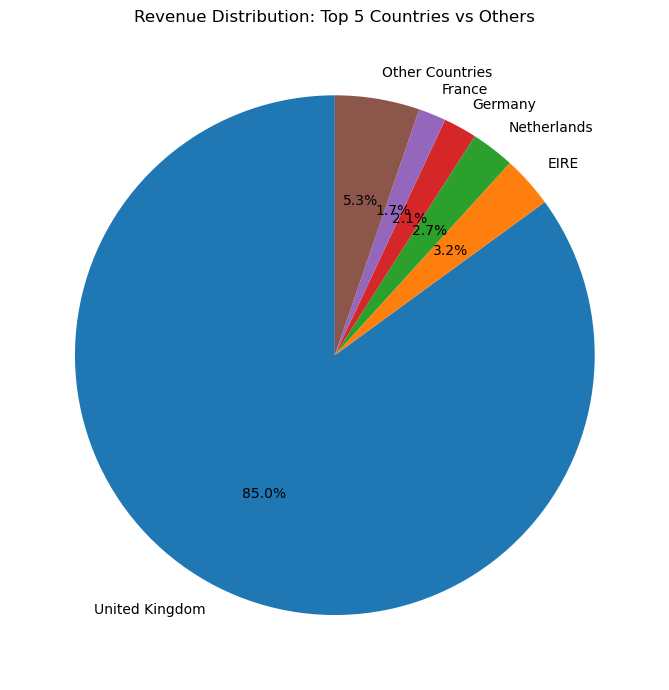

In [10]:
query = """
SELECT
    Country,
    SUM(Quantity * Price) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Country
ORDER BY Total_Revenue DESC;
"""

all_country_revenue = pd.read_sql_query(query, conn)

top_countries = all_country_revenue.head(5).copy()

other_revenue = all_country_revenue.iloc[5:]["Total_Revenue"].sum()

distribution = pd.concat([
    top_countries[["Country", "Total_Revenue"]],
    pd.DataFrame([{
        "Country": "Other Countries",
        "Total_Revenue": other_revenue
    }])
], ignore_index=True)

plt.figure(figsize=(9, 7))
plt.pie(
    distribution["Total_Revenue"],
    labels=distribution["Country"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution: Top 5 Countries vs Others")
plt.tight_layout()
plt.show()